# 01 — Detection and OCR Baseline for a Sign-Reading Robot

**Goal:** build the simplest perception loop for a mobile robot that reads sign boards and acts on them:

`camera frame → object detection (YOLOv8) → text reading (EasyOCR) → command (STOP / LEFT / RIGHT / GO)`

This notebook establishes the baseline. Notebook `02` stress-tests it under realistic camera conditions and builds a robust pipeline.

| Part | Content |
|---|---|
| 1 | OpenCV fundamentals: loading, grayscale, Canny edges |
| 2 | Pre-trained YOLOv8n object detection |
| 3 | Scene text recognition with EasyOCR and a text → action mapping |
| 4 | Testing on your own images (optional) |

In [1]:
# Setup: install dependencies if missing (on Colab, choose Runtime -> Change runtime type -> T4 GPU)
import importlib.util, subprocess, sys
missing = [p for p in ("ultralytics", "easyocr") if importlib.util.find_spec(p) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import warnings
warnings.filterwarnings("ignore")
import torch
DEVICE = "GPU" if torch.cuda.is_available() else "CPU"
print("Dependencies ready | running on:", DEVICE)

Dependencies ready | running on: CPU


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def show(images, titles, cols=3, size=4, save=None):
    """Display BGR or grayscale images in a grid (works in Colab and Jupyter)."""
    rows = (len(images) + cols - 1) // cols
    plt.figure(figsize=(cols * size, rows * size * 0.75))
    for i, (im, t) in enumerate(zip(images, titles)):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(im if im.ndim == 2 else cv2.cvtColor(im, cv2.COLOR_BGR2RGB),
                   cmap="gray" if im.ndim == 2 else None)
        plt.title(t)
        plt.axis("off")
    plt.tight_layout()
    if save:
        plt.savefig(save, dpi=110, bbox_inches="tight")
    plt.show()

## Part 1 — OpenCV fundamentals
Grayscale conversion and edge detection are the first low-level cues a robot uses to find shapes and boundaries.

Image shape (height, width, channels): (1080, 810, 3)


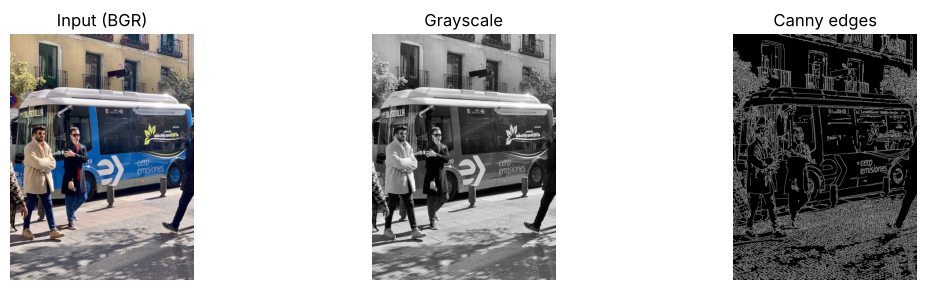

In [3]:
import os, shutil, urllib.request, ultralytics

# Sample street image (bundled with the ultralytics package; downloaded if unavailable)
asset = os.path.join(os.path.dirname(ultralytics.__file__), "assets", "bus.jpg")
if os.path.exists(asset):
    shutil.copy(asset, "bus.jpg")
else:
    urllib.request.urlretrieve("https://ultralytics.com/images/bus.jpg", "bus.jpg")

img = cv2.imread("bus.jpg")                      # OpenCV loads images in BGR order
print("Image shape (height, width, channels):", img.shape)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
edges = cv2.Canny(gray, 100, 200)
show([img, gray, edges], ["Input (BGR)", "Grayscale", "Canny edges"])

## Part 2 — Object detection with YOLOv8
A pre-trained YOLOv8 nano model (COCO, 80 classes) is used without fine-tuning. The nano variant is the smallest and fastest, which matters on robot hardware.

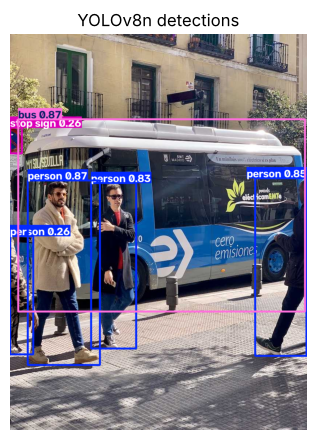

Detected objects:
  bus        confidence=0.87  box=(22,231)-(805,756)
  person     confidence=0.87  box=(48,398)-(245,902)
  person     confidence=0.85  box=(669,392)-(809,877)
  person     confidence=0.83  box=(221,405)-(344,857)
  person     confidence=0.26  box=(0,550)-(63,873)
  stop sign  confidence=0.26  box=(0,254)-(32,324)


In [4]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")
results = model("bus.jpg", verbose=False)

show([results[0].plot()], ["YOLOv8n detections"], cols=1, size=6)

print("Detected objects:")
for box in results[0].boxes:
    name = model.names[int(box.cls)]
    x1, y1, x2, y2 = [int(v) for v in box.xyxy[0]]
    print(f"  {name:10s} confidence={float(box.conf):.2f}  box=({x1},{y1})-({x2},{y2})")

Note that YOLO already recognises a **stop sign** class. Later this is used as a second, independent cue alongside OCR.

## Part 3 — Reading a sign board with OCR
A synthetic sign board (white text on a red board) stands in for a real sign. EasyOCR reads the text, and a simple command table maps it to a robot action — the same logic that will later run inside a ROS 2 node.

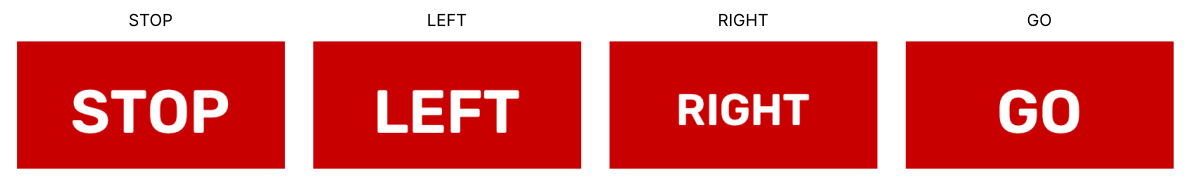

In [5]:
def make_sign(text, w=400, h=200):
    """White text centred on a red board."""
    sign = np.full((h, w, 3), 255, dtype=np.uint8)
    cv2.rectangle(sign, (10, 10), (w - 10, h - 10), (0, 0, 200), -1)
    scale = 3 if len(text) <= 4 else 2.2
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, scale, 8)
    cv2.putText(sign, text, ((w - tw) // 2, (h + th) // 2),
                cv2.FONT_HERSHEY_SIMPLEX, scale, (255, 255, 255), 8)
    return sign

signs = {t: make_sign(t) for t in ["STOP", "LEFT", "RIGHT", "GO"]}
show(list(signs.values()), list(signs.keys()), cols=4, size=3)

In [6]:
import easyocr

reader = easyocr.Reader(["en"], gpu=torch.cuda.is_available(), verbose=False)

COMMANDS = {"STOP": "stop", "LEFT": "turn left", "RIGHT": "turn right", "GO": "move forward"}

def decide(image):
    """Read all text in the image and return the first recognised command."""
    words = [t.upper() for (_, t, _) in reader.readtext(image)]
    action = next((COMMANDS[w] for w in words if w in COMMANDS), "no command - keep moving")
    return words, action

print(f"{'Sign':8s} {'OCR output':18s} Robot action")
print("-" * 46)
for name, sign in signs.items():
    words, action = decide(sign)
    print(f"{name:8s} {str(words):18s} {action}")

Sign     OCR output         Robot action
----------------------------------------------


STOP     ['STOP']           stop


LEFT     ['LEFT']           turn left


RIGHT    ['RIGHT']          turn right


GO       ['GO']             move forward


On a clean, front-facing board the baseline works. A real robot camera, however, sees boards that are **tilted, far away, blurred by motion, poorly lit or noisy**. Notebook `02` measures where this baseline breaks and how to fix it.

## Part 4 — Test on your own images (optional)
Put `.jpg` / `.png` files in a folder called `test_images/` (in Colab: upload them with the file panel) and run the cell below.

In [7]:
import glob

paths = sorted(glob.glob("test_images/*.jpg") + glob.glob("test_images/*.png"))
if not paths:
    print("No images in test_images/ - skipping.")
for p in paths:
    r = model(p, verbose=False)[0]
    show([r.plot()], [os.path.basename(p)], cols=1, size=6)
    print("  YOLO objects:", [model.names[int(b.cls)] for b in r.boxes])
    print("  OCR text:    ", [t for (_, t, _) in reader.readtext(p)])

No images in test_images/ - skipping.
